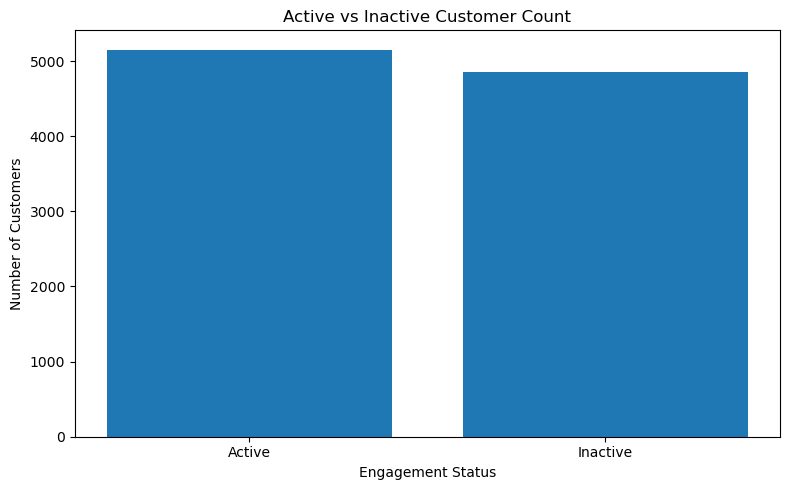

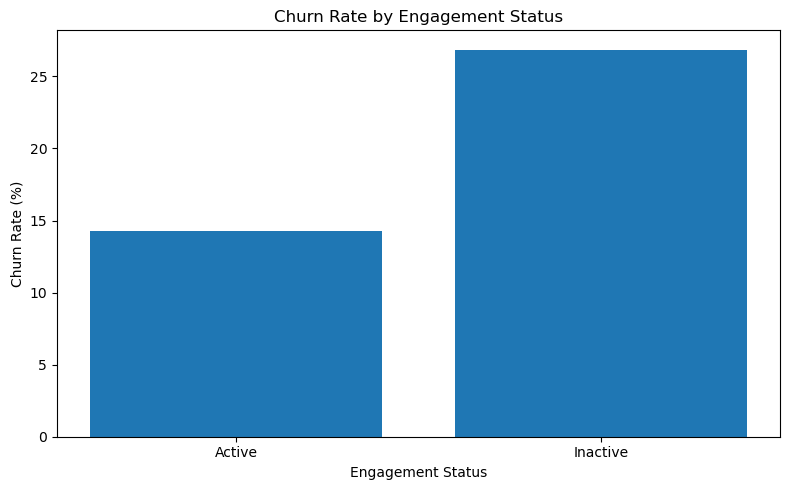

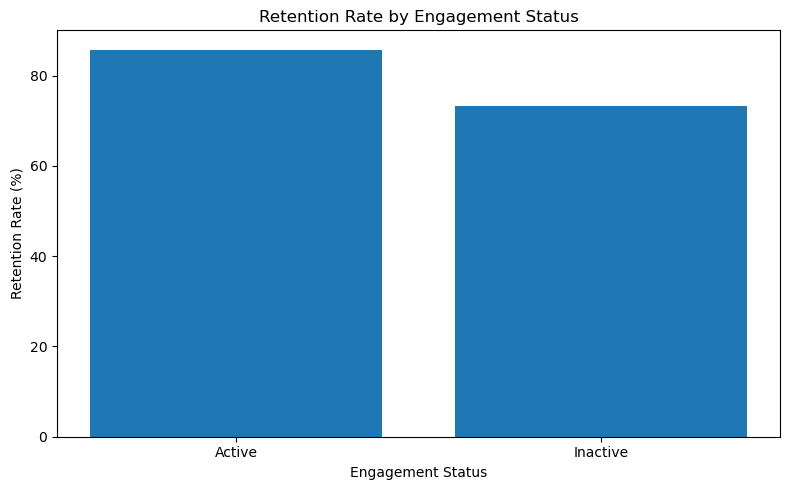

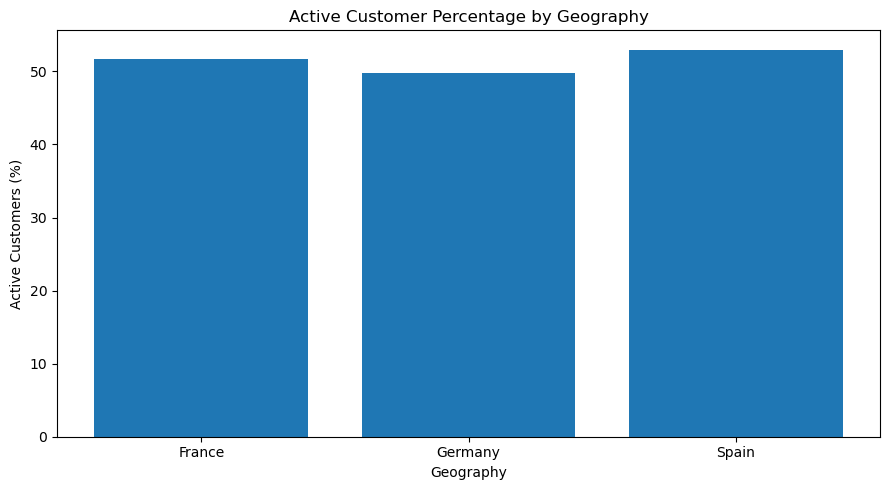

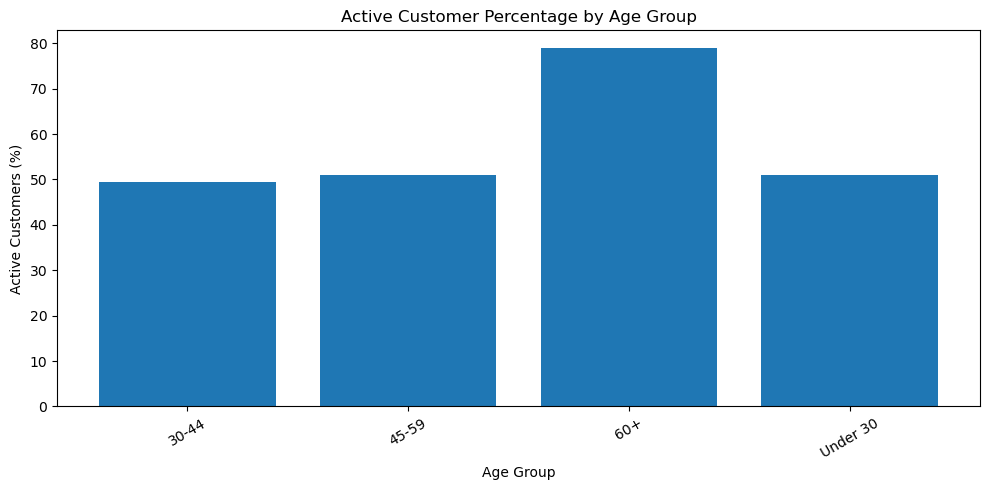

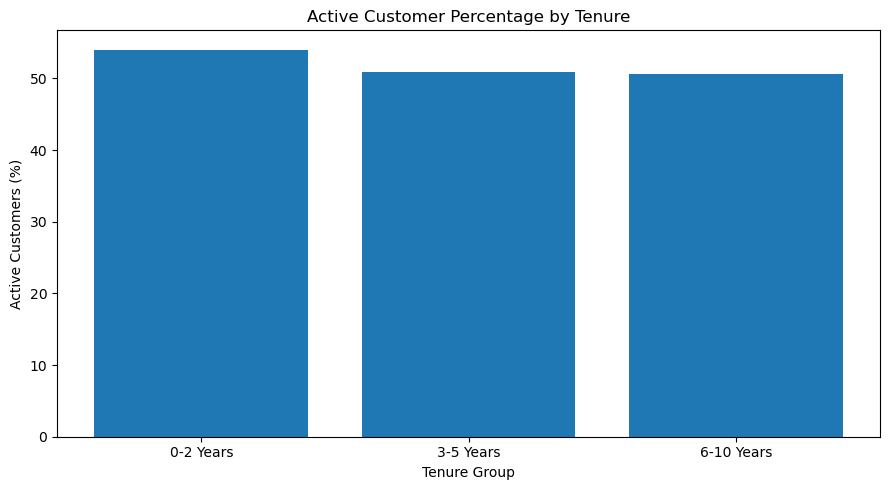

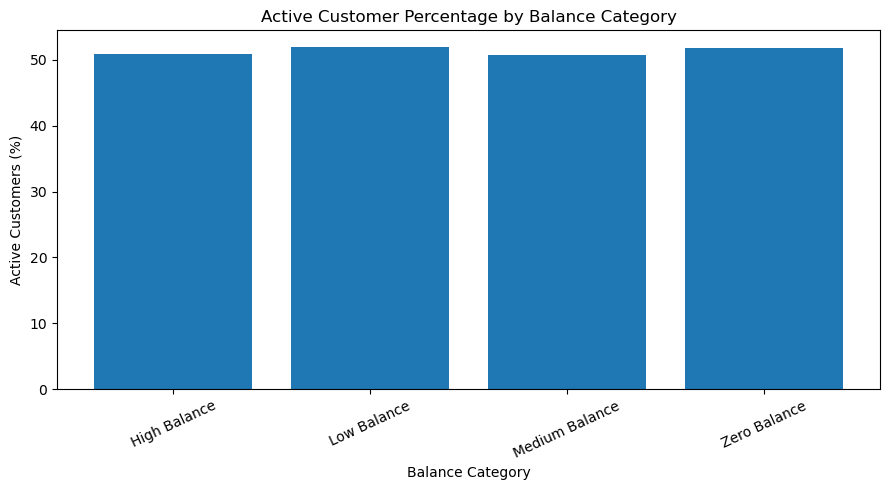

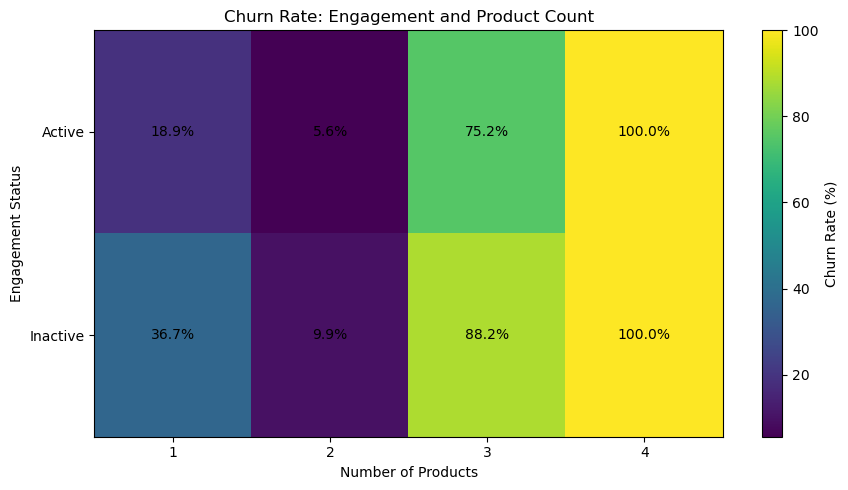


CUSTOMER ENGAGEMENT ANALYTICS COMPLETED SUCCESSFULLY

DATASET INFORMATION
Total customers: 10000
Dataset shape: (10000, 28)

ACTIVITY GROUP COUNTS
Active customers: 5151
Inactive customers: 4849

CHURN AND RETENTION COMPARISON
Active churn rate: 14.27%
Inactive churn rate: 26.85%
Active retention rate: 85.73%
Inactive retention rate: 73.15%

ENGAGEMENT RETENTION METRICS
Retention difference: 12.58 percentage points
Engagement Retention Ratio: 1.172

ENGAGEMENT FINDINGS

Active customers have a lower observed churn rate than inactive customers.
Active customers have a retention advantage of 12.58 percentage points.
Inactive high-balance customers: 784
Geography with highest observed churn: Germany (32.44%)
Age group with highest observed churn: 45-59 (49.45%)
Tenure group with highest observed churn: 0-2 Years (21.15%)

INTERPRETATION LIMITATION
IsActiveMember is an activity-status proxy, not a direct measure of
login frequency, transaction activity or product usage.
These are observed

In [1]:

# Customer Engagement Analytics: Activity, Retention and Customer Segmentation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Project paths and output directories
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\hp\Customer Engagement & Product Utilization Analytics for Retention Strategy"
)

INPUT_FILE = PROJECT_DIR / "data" / "processed" / "European_Bank_Cleaned_Analytical.csv"

TABLE_DIR = PROJECT_DIR / "outputs" / "tables" / "engagement"
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures" / "engagement"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_FILE}\n"
        "Check that Phase 2 completed successfully and the file exists."
    )

# ------------------------------------------------------------
# Load and standardize the analytical dataset
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

def normalize_column_name(column):
    return "".join(
        character.lower()
        for character in str(column)
        if character.isalnum()
    )

df.columns = [normalize_column_name(col) for col in df.columns]

required_columns = [
    "customerid",
    "geography",
    "age",
    "tenure",
    "balance",
    "numofproducts",
    "isactivemember",
    "exited"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Convert important fields to numeric values
numeric_columns = [
    "age", "tenure", "balance",
    "numofproducts", "isactivemember", "exited"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[required_columns].isnull().any().any():
    raise ValueError(
        "Missing or non-numeric values found in required analytical columns."
    )

if not set(df["isactivemember"].unique()).issubset({0, 1}):
    raise ValueError("IsActiveMember must contain only 0 and 1.")

if not set(df["exited"].unique()).issubset({0, 1}):
    raise ValueError("Exited must contain only 0 and 1.")

df["isactivemember"] = df["isactivemember"].astype(int)
df["exited"] = df["exited"].astype(int)

# ------------------------------------------------------------
# Define engagement measurement approach
# ------------------------------------------------------------

# IsActiveMember = 1: Active customer
# IsActiveMember = 0: Inactive customer
# Exited = 1: Churned customer
# Exited = 0: Retained customer

df["activity_status"] = np.where(
    df["isactivemember"] == 1,
    "Active",
    "Inactive"
)

df["customer_status"] = np.where(
    df["exited"] == 1,
    "Churned",
    "Retained"
)

# Create analytical segments only if they are not already available.
# Existing Phase 2 categories are preserved.

if "agegroup" not in df.columns:
    df["agegroup"] = pd.cut(
        df["age"],
        bins=[17, 30, 40, 50, 60, 70, 100],
        labels=[
            "18-30", "31-40", "41-50",
            "51-60", "61-70", "71+"
        ],
        include_lowest=True
    )

if "tenuregroup" not in df.columns:
    df["tenuregroup"] = pd.cut(
        df["tenure"],
        bins=[-1, 2, 5, 8, 10],
        labels=["0-2 Years", "3-5 Years", "6-8 Years", "9-10 Years"]
    )

if "balancecategory" not in df.columns:
    positive_balance = df.loc[df["balance"] > 0, "balance"]

    if len(positive_balance) > 0:
        median_balance = positive_balance.median()
        upper_quartile = positive_balance.quantile(0.75)

        df["balancecategory"] = np.select(
            [
                df["balance"] == 0,
                df["balance"] < median_balance,
                df["balance"] < upper_quartile
            ],
            [
                "Zero Balance",
                "Low Balance",
                "Medium Balance"
            ],
            default="High Balance"
        )
    else:
        df["balancecategory"] = "Zero Balance"

if "productcountcategory" not in df.columns:
    df["productcountcategory"] = np.where(
        df["numofproducts"] == 1,
        "Single Product",
        "Multiple Products"
    )

# ------------------------------------------------------------
# Calculate active and inactive customer counts
# ------------------------------------------------------------

total_customers = len(df)

active_customers = df[df["isactivemember"] == 1]
inactive_customers = df[df["isactivemember"] == 0]

active_count = len(active_customers)
inactive_count = len(inactive_customers)

active_churn_count = int(active_customers["exited"].sum())
inactive_churn_count = int(inactive_customers["exited"].sum())

# ------------------------------------------------------------
# Calculate churn and retention rates
# ------------------------------------------------------------

active_churn_rate = (
    active_churn_count / active_count * 100
    if active_count else 0
)

inactive_churn_rate = (
    inactive_churn_count / inactive_count * 100
    if inactive_count else 0
)

active_retention_rate = 100 - active_churn_rate
inactive_retention_rate = 100 - inactive_churn_rate

# ------------------------------------------------------------
# Compare engagement between activity groups
# ------------------------------------------------------------

activity_metrics = (
    df.groupby("activity_status", observed=True)
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum"),
        average_age=("age", "mean"),
        average_tenure=("tenure", "mean"),
        average_balance=("balance", "mean"),
        average_products=("numofproducts", "mean")
    )
    .reset_index()
)

activity_metrics["churn_rate_pct"] = (
    activity_metrics["churned_customers"]
    / activity_metrics["customer_count"] * 100
)

activity_metrics["retention_rate_pct"] = (
    100 - activity_metrics["churn_rate_pct"]
)

activity_metrics["customer_share_pct"] = (
    activity_metrics["customer_count"] / total_customers * 100
)

# ------------------------------------------------------------
# Calculate engagement retention difference and ratio
# ------------------------------------------------------------

engagement_retention_difference = (
    active_retention_rate - inactive_retention_rate
)

engagement_retention_ratio = (
    active_retention_rate / inactive_retention_rate
    if inactive_retention_rate != 0 else np.nan
)

overall_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Active Customers",
        "Inactive Customers",
        "Active Customer Share (%)",
        "Inactive Customer Share (%)",
        "Active Customer Churn Count",
        "Inactive Customer Churn Count",
        "Active Customer Churn Rate (%)",
        "Inactive Customer Churn Rate (%)",
        "Active Customer Retention Rate (%)",
        "Inactive Customer Retention Rate (%)",
        "Engagement Retention Difference (Percentage Points)",
        "Engagement Retention Ratio"
    ],
    "Value": [
        total_customers,
        active_count,
        inactive_count,
        active_count / total_customers * 100,
        inactive_count / total_customers * 100,
        active_churn_count,
        inactive_churn_count,
        active_churn_rate,
        inactive_churn_rate,
        active_retention_rate,
        inactive_retention_rate,
        engagement_retention_difference,
        engagement_retention_ratio
    ]
})

# ------------------------------------------------------------
# Analyze engagement by geography, age, tenure and balance
# ------------------------------------------------------------

def calculate_segment_engagement(data, segment_column):
    result = (
        data.groupby(segment_column, observed=True, dropna=False)
        .agg(
            customer_count=("customerid", "count"),
            active_customers=("isactivemember", "sum"),
            churned_customers=("exited", "sum")
        )
        .reset_index()
    )

    result["active_customer_pct"] = (
        result["active_customers"]
        / result["customer_count"] * 100
    )

    result["churn_rate_pct"] = (
        result["churned_customers"]
        / result["customer_count"] * 100
    )

    result["retention_rate_pct"] = (
        100 - result["churn_rate_pct"]
    )

    return result

geography_engagement = calculate_segment_engagement(
    df, "geography"
)

age_engagement = calculate_segment_engagement(
    df, "agegroup"
)

tenure_engagement = calculate_segment_engagement(
    df, "tenuregroup"
)

balance_engagement = calculate_segment_engagement(
    df, "balancecategory"
)

# ------------------------------------------------------------
# Analyze engagement and product-count combinations
# ------------------------------------------------------------

activity_product_analysis = (
    df.groupby(
        ["activity_status", "numofproducts"],
        observed=True
    )
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

activity_product_analysis["churn_rate_pct"] = (
    activity_product_analysis["churned_customers"]
    / activity_product_analysis["customer_count"] * 100
)

activity_product_analysis["retention_rate_pct"] = (
    100 - activity_product_analysis["churn_rate_pct"]
)

# ------------------------------------------------------------
# Identify inactive customer segments
# ------------------------------------------------------------

inactive_segment_analysis = (
    inactive_customers.groupby(
        [
            "geography",
            "agegroup",
            "tenuregroup",
            "balancecategory",
            "productcountcategory"
        ],
        observed=True,
        dropna=False
    )
    .agg(
        inactive_customer_count=("customerid", "count"),
        churned_customers=("exited", "sum"),
        average_balance=("balance", "mean"),
        average_age=("age", "mean"),
        average_products=("numofproducts", "mean")
    )
    .reset_index()
)

inactive_segment_analysis["churn_rate_pct"] = (
    inactive_segment_analysis["churned_customers"]
    / inactive_segment_analysis["inactive_customer_count"] * 100
)

inactive_segment_analysis = inactive_segment_analysis.sort_values(
    ["inactive_customer_count", "churn_rate_pct"],
    ascending=[False, False]
)

# Focused inactive customer analysis
inactive_high_balance = inactive_customers[
    inactive_customers["balancecategory"].astype(str).str.lower()
    .str.contains("high", na=False)
]

inactive_high_balance_summary = pd.DataFrame({
    "Metric": [
        "Inactive High-Balance Customers",
        "Churned Inactive High-Balance Customers",
        "Inactive High-Balance Churn Rate (%)",
        "Average Balance of Inactive High-Balance Customers"
    ],
    "Value": [
        len(inactive_high_balance),
        int(inactive_high_balance["exited"].sum()),
        (
            inactive_high_balance["exited"].mean() * 100
            if len(inactive_high_balance) else 0
        ),
        (
            inactive_high_balance["balance"].mean()
            if len(inactive_high_balance) else 0
        )
    ]
})

# ------------------------------------------------------------
# Generate engagement-related visualizations
# ------------------------------------------------------------

# Active versus inactive customer count
plt.figure(figsize=(8, 5))
plt.bar(
    ["Active", "Inactive"],
    [active_count, inactive_count]
)
plt.title("Active vs Inactive Customer Count")
plt.xlabel("Engagement Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "active_inactive_customer_count.png", dpi=300)
plt.show()
plt.close()

# Churn rate comparison
plt.figure(figsize=(8, 5))
plt.bar(
    ["Active", "Inactive"],
    [active_churn_rate, inactive_churn_rate]
)
plt.title("Churn Rate by Engagement Status")
plt.xlabel("Engagement Status")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "churn_rate_by_engagement.png", dpi=300)
plt.show()
plt.close()

# Retention rate comparison
plt.figure(figsize=(8, 5))
plt.bar(
    ["Active", "Inactive"],
    [active_retention_rate, inactive_retention_rate]
)
plt.title("Retention Rate by Engagement Status")
plt.xlabel("Engagement Status")
plt.ylabel("Retention Rate (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "retention_rate_by_engagement.png", dpi=300)
plt.show()
plt.close()

# Geography engagement
plt.figure(figsize=(9, 5))
plt.bar(
    geography_engagement["geography"].astype(str),
    geography_engagement["active_customer_pct"]
)
plt.title("Active Customer Percentage by Geography")
plt.xlabel("Geography")
plt.ylabel("Active Customers (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "engagement_by_geography.png", dpi=300)
plt.show()
plt.close()

# Age group engagement
plt.figure(figsize=(10, 5))
plt.bar(
    age_engagement["agegroup"].astype(str),
    age_engagement["active_customer_pct"]
)
plt.title("Active Customer Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Active Customers (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "engagement_by_age_group.png", dpi=300)
plt.show()
plt.close()

# Tenure engagement
plt.figure(figsize=(9, 5))
plt.bar(
    tenure_engagement["tenuregroup"].astype(str),
    tenure_engagement["active_customer_pct"]
)
plt.title("Active Customer Percentage by Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Active Customers (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "engagement_by_tenure.png", dpi=300)
plt.show()
plt.close()

# Balance category engagement
plt.figure(figsize=(9, 5))
plt.bar(
    balance_engagement["balancecategory"].astype(str),
    balance_engagement["active_customer_pct"]
)
plt.title("Active Customer Percentage by Balance Category")
plt.xlabel("Balance Category")
plt.ylabel("Active Customers (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "engagement_by_balance_category.png", dpi=300)
plt.show()
plt.close()

# Activity and product-count churn heatmap
heatmap_data = activity_product_analysis.pivot(
    index="activity_status",
    columns="numofproducts",
    values="churn_rate_pct"
)

plt.figure(figsize=(9, 5))
plt.imshow(heatmap_data, aspect="auto")
plt.colorbar(label="Churn Rate (%)")
plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)
plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)
plt.xlabel("Number of Products")
plt.ylabel("Engagement Status")
plt.title("Churn Rate: Engagement and Product Count")

for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[row, col]
        if pd.notna(value):
            plt.text(col, row, f"{value:.1f}%", ha="center", va="center")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "engagement_product_churn_heatmap.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------------------
# Summarize engagement-related retention findings
# ------------------------------------------------------------

if active_churn_rate < inactive_churn_rate:
    engagement_finding = (
        "Active customers have a lower observed churn rate than inactive customers."
    )
elif active_churn_rate > inactive_churn_rate:
    engagement_finding = (
        "Active customers have a higher observed churn rate than inactive customers."
    )
else:
    engagement_finding = (
        "Active and inactive customers have equal observed churn rates."
    )

if engagement_retention_difference > 0:
    retention_finding = (
        f"Active customers have a retention advantage of "
        f"{engagement_retention_difference:.2f} percentage points."
    )
elif engagement_retention_difference < 0:
    retention_finding = (
        f"Inactive customers have a retention advantage of "
        f"{abs(engagement_retention_difference):.2f} percentage points."
    )
else:
    retention_finding = "Both activity groups have equal retention rates."

highest_churn_geo = geography_engagement.sort_values(
    "churn_rate_pct", ascending=False
).head(1)

highest_churn_age = age_engagement.sort_values(
    "churn_rate_pct", ascending=False
).head(1)

highest_churn_tenure = tenure_engagement.sort_values(
    "churn_rate_pct", ascending=False
).head(1)

findings = [
    "ENGAGEMENT ANALYTICS FINDINGS",
    "========================================",
    f"Total customers analyzed: {total_customers}",
    f"Active customers: {active_count}",
    f"Inactive customers: {inactive_count}",
    f"Active customer churn rate: {active_churn_rate:.2f}%",
    f"Inactive customer churn rate: {inactive_churn_rate:.2f}%",
    f"Active customer retention rate: {active_retention_rate:.2f}%",
    f"Inactive customer retention rate: {inactive_retention_rate:.2f}%",
    f"Engagement retention difference: {engagement_retention_difference:.2f} percentage points",
    f"Engagement Retention Ratio: {engagement_retention_ratio:.3f}",
    "",
    engagement_finding,
    retention_finding,
    f"Inactive high-balance customers: {len(inactive_high_balance)}"
]

if not highest_churn_geo.empty:
    findings.append(
        f"Geography with highest observed churn: "
        f"{highest_churn_geo.iloc[0]['geography']} "
        f"({highest_churn_geo.iloc[0]['churn_rate_pct']:.2f}%)"
    )

if not highest_churn_age.empty:
    findings.append(
        f"Age group with highest observed churn: "
        f"{highest_churn_age.iloc[0]['agegroup']} "
        f"({highest_churn_age.iloc[0]['churn_rate_pct']:.2f}%)"
    )

if not highest_churn_tenure.empty:
    findings.append(
        f"Tenure group with highest observed churn: "
        f"{highest_churn_tenure.iloc[0]['tenuregroup']} "
        f"({highest_churn_tenure.iloc[0]['churn_rate_pct']:.2f}%)"
    )

findings.extend([
    "",
    "INTERPRETATION LIMITATION",
    "IsActiveMember is an activity-status proxy, not a direct measure of",
    "login frequency, transaction activity or product usage.",
    "These are observed associations, not proof of causation."
])

# ------------------------------------------------------------
# Save analytical tables, findings and processed analysis data
# ------------------------------------------------------------

tables_to_save = {
    "overall_engagement_summary": overall_summary,
    "activity_group_metrics": activity_metrics,
    "geography_engagement": geography_engagement,
    "age_group_engagement": age_engagement,
    "tenure_engagement": tenure_engagement,
    "balance_category_engagement": balance_engagement,
    "activity_product_analysis": activity_product_analysis,
    "inactive_customer_segments": inactive_segment_analysis,
    "inactive_high_balance_summary": inactive_high_balance_summary
}

for filename, table in tables_to_save.items():
    table.to_csv(
        TABLE_DIR / f"{filename}.csv",
        index=False
    )

with open(
    TABLE_DIR / "engagement_analytics_findings.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(findings))

df.to_csv(
    TABLE_DIR / "engagement_analysis_dataset.csv",
    index=False
)

# ------------------------------------------------------------
# Final output and validation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CUSTOMER ENGAGEMENT ANALYTICS COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nDATASET INFORMATION")
print(f"Total customers: {total_customers}")
print(f"Dataset shape: {df.shape}")

print("\nACTIVITY GROUP COUNTS")
print(f"Active customers: {active_count}")
print(f"Inactive customers: {inactive_count}")

print("\nCHURN AND RETENTION COMPARISON")
print(f"Active churn rate: {active_churn_rate:.2f}%")
print(f"Inactive churn rate: {inactive_churn_rate:.2f}%")
print(f"Active retention rate: {active_retention_rate:.2f}%")
print(f"Inactive retention rate: {inactive_retention_rate:.2f}%")

print("\nENGAGEMENT RETENTION METRICS")
print(
    f"Retention difference: "
    f"{engagement_retention_difference:.2f} percentage points"
)
print(
    f"Engagement Retention Ratio: "
    f"{engagement_retention_ratio:.3f}"
)

print("\nENGAGEMENT FINDINGS")
for finding in findings[11:]:
    print(finding)

print("\nSAVED ANALYTICAL TABLES")
for filename in tables_to_save:
    print(f"- {filename}.csv")

print("\nSAVED VISUALIZATIONS")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"- {path.name}")

print("\nOUTPUT LOCATIONS")
print(f"Tables: {TABLE_DIR}")
print(f"Figures: {FIGURE_DIR}")

print("\nPHASE 4 VALIDATION")
print(
    "Customer count reconciliation:",
    active_count + inactive_count == total_customers
)
print(
    "Churn count reconciliation:",
    active_churn_count + inactive_churn_count == int(df["exited"].sum())
)
print(
    "Retention and churn percentages valid:",
    np.isclose(active_retention_rate + active_churn_rate, 100)
    and np.isclose(inactive_retention_rate + inactive_churn_rate, 100)
)

print("\nPHASE 4 EXECUTION FINISHED.")


## Product Adoption Analytics

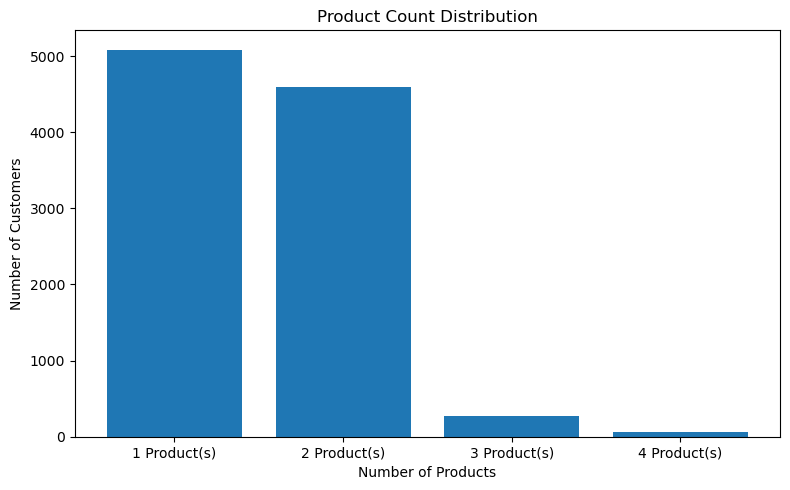

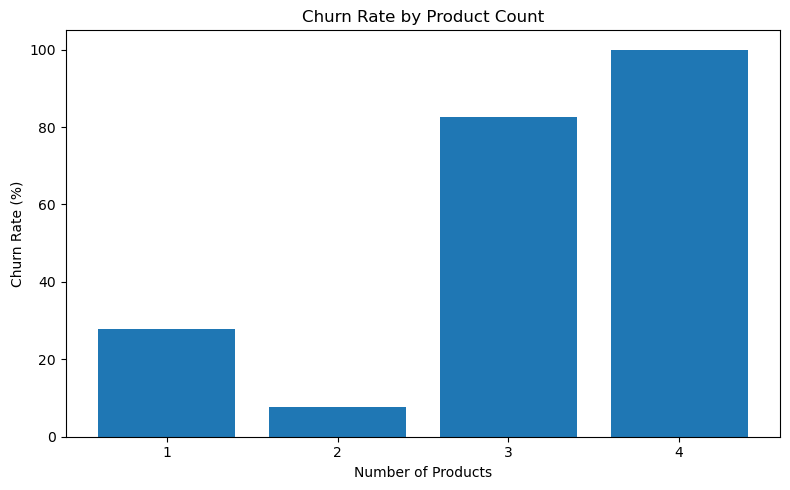

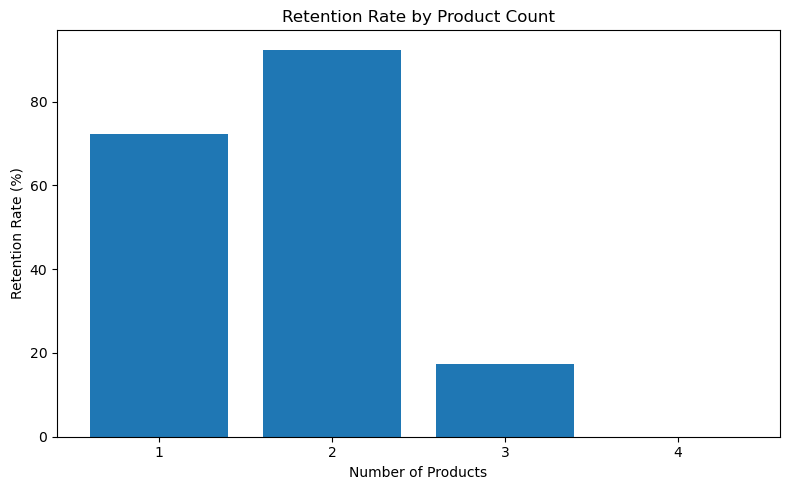

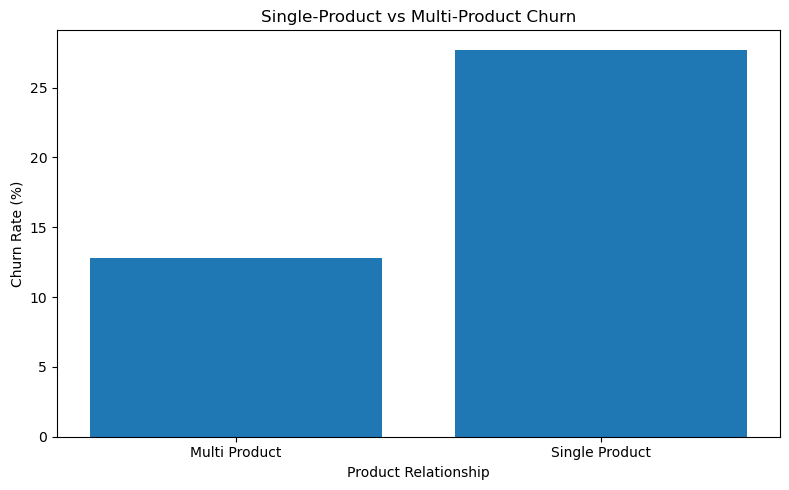

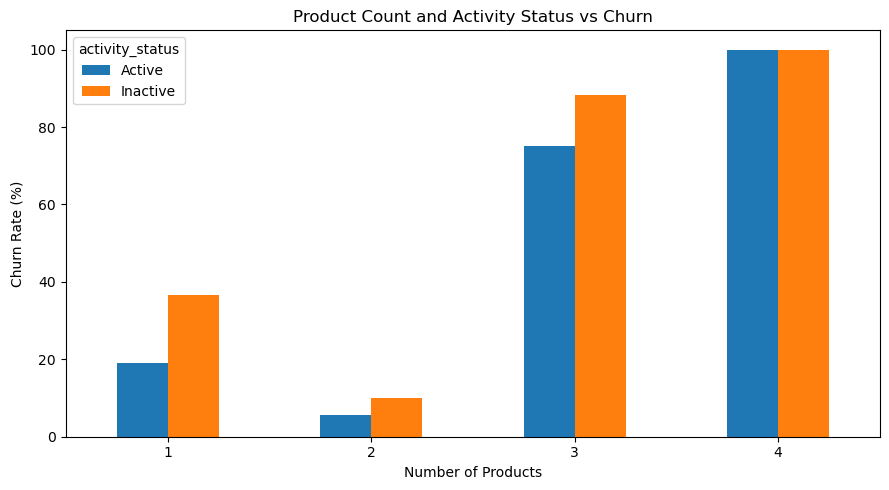

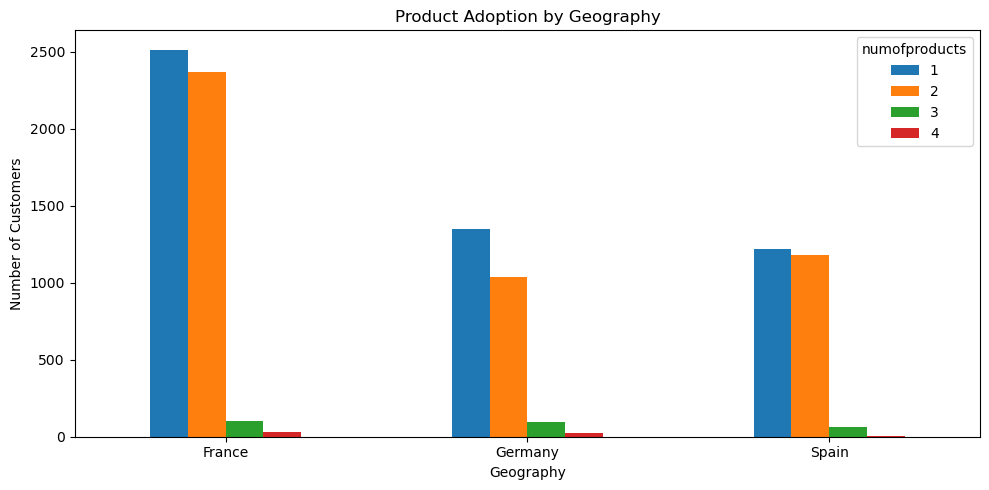

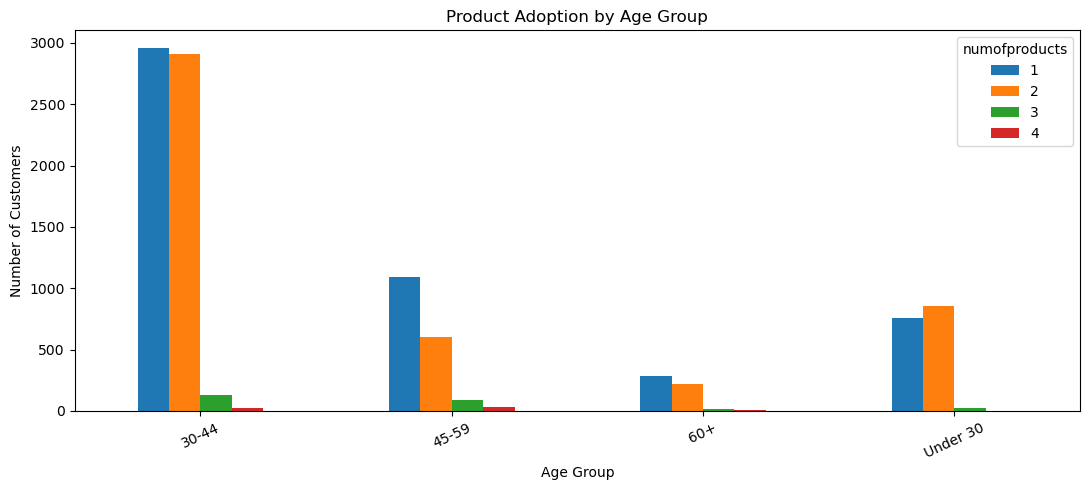

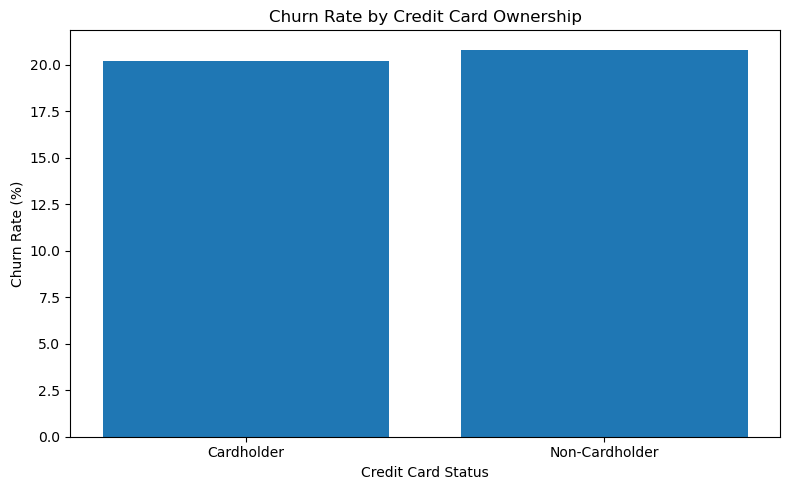


PRODUCT ADOPTION ANALYTICS COMPLETED SUCCESSFULLY

DATASET SUMMARY
Total customers: 10000
Average products per customer: 1.530
Product Depth Index: 1.530

PRODUCT COUNT DISTRIBUTION
 product_count  customer_count  customer_share_pct product_label
             1            5084               50.84  1 Product(s)
             2            4590               45.90  2 Product(s)
             3             266                2.66  3 Product(s)
             4              60                0.60  4 Product(s)

CHURN AND RETENTION BY PRODUCT COUNT
 numofproducts  customer_count  churned_customers  retained_customers  churn_rate_pct  retention_rate_pct
             1            5084               1409                3675       27.714398           72.285602
             2            4590                348                4242        7.581699           92.418301
             3             266                220                  46       82.706767           17.293233
             4              60

In [6]:

# Product Adoption, Retention and Cross-Sell Analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Project paths and output directories
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\hp\Customer Engagement & Product Utilization Analytics for Retention Strategy"
)

INPUT_FILE = (
    PROJECT_DIR / "data" / "processed" /
    "European_Bank_Cleaned_Analytical.csv"
)

TABLE_DIR = PROJECT_DIR / "outputs" / "tables" / "product_adoption"
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures" / "product_adoption"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_FILE}"
    )

# ------------------------------------------------------------
# Load and validate analytical dataset
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

def normalize_column_name(column):
    return "".join(
        character.lower()
        for character in str(column)
        if character.isalnum()
    )

df.columns = [normalize_column_name(col) for col in df.columns]

required_columns = [
    "customerid",
    "geography",
    "age",
    "numofproducts",
    "isactivemember",
    "hascrcard",
    "exited"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

for col in [
    "age",
    "numofproducts",
    "isactivemember",
    "hascrcard",
    "exited"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[required_columns].isnull().any().any():
    raise ValueError(
        "Missing or invalid values found in required columns."
    )

for col in ["isactivemember", "hascrcard", "exited"]:
    if not set(df[col].unique()).issubset({0, 1}):
        raise ValueError(f"{col} must contain only 0 and 1.")

if not set(df["numofproducts"].unique()).issubset({1, 2, 3, 4}):
    raise ValueError("Unexpected product count detected.")

df["numofproducts"] = df["numofproducts"].astype(int)
df["isactivemember"] = df["isactivemember"].astype(int)
df["hascrcard"] = df["hascrcard"].astype(int)
df["exited"] = df["exited"].astype(int)

total_customers = len(df)

# ------------------------------------------------------------
# Create product adoption categories
# ------------------------------------------------------------

df["product_adoption_category"] = np.select(
    [
        df["numofproducts"] == 1,
        df["numofproducts"] == 2,
        df["numofproducts"] == 3,
        df["numofproducts"] == 4
    ],
    [
        "One Product",
        "Two Products",
        "Three Products",
        "Four Products"
    ],
    default="Other"
)

df["product_relationship"] = np.where(
    df["numofproducts"] == 1,
    "Single Product",
    "Multi Product"
)

df["customer_status"] = np.where(
    df["exited"] == 1,
    "Churned",
    "Retained"
)

df["activity_status"] = np.where(
    df["isactivemember"] == 1,
    "Active",
    "Inactive"
)

df["credit_card_status"] = np.where(
    df["hascrcard"] == 1,
    "Cardholder",
    "Non-Cardholder"
)

if "agegroup" not in df.columns:
    df["agegroup"] = pd.cut(
        df["age"],
        bins=[17, 30, 40, 50, 60, 70, 100],
        labels=[
            "18-30", "31-40", "41-50",
            "51-60", "61-70", "71+"
        ],
        include_lowest=True
    )

# ------------------------------------------------------------
# Analyze product-count distribution
# ------------------------------------------------------------

product_distribution = (
    df["numofproducts"]
    .value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
    .rename_axis("product_count")
    .reset_index(name="customer_count")
)

product_distribution["customer_share_pct"] = (
    product_distribution["customer_count"]
    / total_customers * 100
)

product_distribution["product_label"] = (
    product_distribution["product_count"].astype(str)
    + " Product(s)"
)

# ------------------------------------------------------------
# Calculate average products and Product Depth Index
# ------------------------------------------------------------

average_products_per_customer = df["numofproducts"].mean()

product_depth_index = (
    df["numofproducts"].sum() / total_customers
)

product_depth_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Product Relationships",
        "Average Products per Customer",
        "Product Depth Index"
    ],
    "Value": [
        total_customers,
        df["numofproducts"].sum(),
        average_products_per_customer,
        product_depth_index
    ]
})

# ------------------------------------------------------------
# Calculate churn and retention by product count
# ------------------------------------------------------------

product_churn_retention = (
    df.groupby("numofproducts")
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum"),
        retained_customers=("exited", lambda x: (x == 0).sum())
    )
    .reindex([1, 2, 3, 4], fill_value=0)
    .reset_index()
)

product_churn_retention["churn_rate_pct"] = np.where(
    product_churn_retention["customer_count"] > 0,
    product_churn_retention["churned_customers"]
    / product_churn_retention["customer_count"] * 100,
    np.nan
)

product_churn_retention["retention_rate_pct"] = np.where(
    product_churn_retention["customer_count"] > 0,
    product_churn_retention["retained_customers"]
    / product_churn_retention["customer_count"] * 100,
    np.nan
)

# ------------------------------------------------------------
# Compare single-product and multi-product customers
# ------------------------------------------------------------

single_multi_comparison = (
    df.groupby("product_relationship")
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum"),
        retained_customers=("exited", lambda x: (x == 0).sum()),
        average_products=("numofproducts", "mean"),
        active_customers=("isactivemember", "sum")
    )
    .reset_index()
)

single_multi_comparison["customer_share_pct"] = (
    single_multi_comparison["customer_count"]
    / total_customers * 100
)

single_multi_comparison["churn_rate_pct"] = (
    single_multi_comparison["churned_customers"]
    / single_multi_comparison["customer_count"] * 100
)

single_multi_comparison["retention_rate_pct"] = (
    100 - single_multi_comparison["churn_rate_pct"]
)

single_multi_comparison["active_customer_pct"] = (
    single_multi_comparison["active_customers"]
    / single_multi_comparison["customer_count"] * 100
)

# ------------------------------------------------------------
# Analyze one-, two-, three- and four-product customers
# ------------------------------------------------------------

individual_product_analyses = []

for product_count in [1, 2, 3, 4]:

    segment = df[df["numofproducts"] == product_count]

    if len(segment) == 0:
        summary = {
            "product_count": product_count,
            "customer_count": 0,
            "churned_customers": 0,
            "retained_customers": 0,
            "churn_rate_pct": np.nan,
            "retention_rate_pct": np.nan,
            "active_customer_pct": np.nan,
            "average_age": np.nan
        }
    else:
        summary = {
            "product_count": product_count,
            "customer_count": len(segment),
            "churned_customers": int(segment["exited"].sum()),
            "retained_customers": int((segment["exited"] == 0).sum()),
            "churn_rate_pct": segment["exited"].mean() * 100,
            "retention_rate_pct": (1 - segment["exited"].mean()) * 100,
            "active_customer_pct": segment["isactivemember"].mean() * 100,
            "average_age": segment["age"].mean()
        }

    individual_product_analyses.append(summary)

individual_product_summary = pd.DataFrame(
    individual_product_analyses
)

# ------------------------------------------------------------
# Analyze product count with activity status
# ------------------------------------------------------------

product_activity_analysis = (
    df.groupby(
        ["numofproducts", "activity_status"],
        observed=True
    )
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

product_activity_analysis["churn_rate_pct"] = (
    product_activity_analysis["churned_customers"]
    / product_activity_analysis["customer_count"] * 100
)

product_activity_analysis["retention_rate_pct"] = (
    100 - product_activity_analysis["churn_rate_pct"]
)

# ------------------------------------------------------------
# Analyze product count by geography
# ------------------------------------------------------------

product_geography_analysis = (
    df.groupby(
        ["geography", "numofproducts"],
        observed=True
    )
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

product_geography_analysis["geography_customer_share_pct"] = (
    product_geography_analysis["customer_count"]
    / product_geography_analysis.groupby("geography")[
        "customer_count"
    ].transform("sum") * 100
)

product_geography_analysis["churn_rate_pct"] = (
    product_geography_analysis["churned_customers"]
    / product_geography_analysis["customer_count"] * 100
)

# ------------------------------------------------------------
# Analyze product count by age group
# ------------------------------------------------------------

product_age_analysis = (
    df.groupby(
        ["agegroup", "numofproducts"],
        observed=True
    )
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

product_age_analysis["age_group_customer_share_pct"] = (
    product_age_analysis["customer_count"]
    / product_age_analysis.groupby("agegroup")[
        "customer_count"
    ].transform("sum") * 100
)

product_age_analysis["churn_rate_pct"] = (
    product_age_analysis["churned_customers"]
    / product_age_analysis["customer_count"] * 100
)

# ------------------------------------------------------------
# Analyze credit card ownership and churn
# ------------------------------------------------------------

credit_card_analysis = (
    df.groupby("credit_card_status")
    .agg(
        customer_count=("customerid", "count"),
        churned_customers=("exited", "sum"),
        retained_customers=("exited", lambda x: (x == 0).sum())
    )
    .reset_index()
)

credit_card_analysis["churn_rate_pct"] = (
    credit_card_analysis["churned_customers"]
    / credit_card_analysis["customer_count"] * 100
)

credit_card_analysis["retention_rate_pct"] = (
    100 - credit_card_analysis["churn_rate_pct"]
)

# ------------------------------------------------------------
# Calculate Credit Card Stickiness Score
# ------------------------------------------------------------

cardholder_retention = (
    (df.loc[df["hascrcard"] == 1, "exited"] == 0).mean() * 100
    if (df["hascrcard"] == 1).any() else np.nan
)

non_cardholder_retention = (
    (df.loc[df["hascrcard"] == 0, "exited"] == 0).mean() * 100
    if (df["hascrcard"] == 0).any() else np.nan
)

credit_card_stickiness_score = (
    cardholder_retention - non_cardholder_retention
    if pd.notna(cardholder_retention)
    and pd.notna(non_cardholder_retention)
    else np.nan
)

credit_card_stickiness_summary = pd.DataFrame({
    "Metric": [
        "Cardholder Retention Rate (%)",
        "Non-Cardholder Retention Rate (%)",
        "Credit Card Stickiness Score (Percentage Points)"
    ],
    "Value": [
        cardholder_retention,
        non_cardholder_retention,
        credit_card_stickiness_score
    ]
})

# ------------------------------------------------------------
# Identify product-adoption opportunities
# ------------------------------------------------------------

retained_single_product = df[
    (df["numofproducts"] == 1) &
    (df["exited"] == 0)
].copy()

retained_single_product_summary = pd.DataFrame({
    "Metric": [
        "Retained Single-Product Customers",
        "Active Retained Single-Product Customers",
        "Inactive Retained Single-Product Customers",
        "Average Age",
        "Credit Card Ownership Rate (%)"
    ],
    "Value": [
        len(retained_single_product),
        int(retained_single_product["isactivemember"].sum()),
        int((retained_single_product["isactivemember"] == 0).sum()),
        (
            retained_single_product["age"].mean()
            if len(retained_single_product) else np.nan
        ),
        (
            retained_single_product["hascrcard"].mean() * 100
            if len(retained_single_product) else np.nan
        )
    ]
})

cross_sell_segment_analysis = (
    retained_single_product.groupby(
        ["geography", "activity_status", "agegroup"],
        observed=True,
        dropna=False
    )
    .agg(
        customer_count=("customerid", "count"),
        average_age=("age", "mean")
    )
    .reset_index()
    .sort_values("customer_count", ascending=False)
)

# ------------------------------------------------------------
# Summarize product-related retention findings
# ------------------------------------------------------------

highest_churn_product = (
    product_churn_retention
    .dropna(subset=["churn_rate_pct"])
    .sort_values("churn_rate_pct", ascending=False)
)

if not highest_churn_product.empty:
    highest_product_count = int(
        highest_churn_product.iloc[0]["numofproducts"]
    )
    highest_product_churn_rate = float(
        highest_churn_product.iloc[0]["churn_rate_pct"]
    )
else:
    highest_product_count = None
    highest_product_churn_rate = np.nan

findings = [
    "PRODUCT ADOPTION ANALYTICS FINDINGS",
    "========================================",
    f"Total customers analyzed: {total_customers}",
    f"Average products per customer: {average_products_per_customer:.3f}",
    f"Product Depth Index: {product_depth_index:.3f}",
    "",
    "PRODUCT COUNT RETENTION"
]

for _, row in product_churn_retention.iterrows():
    if row["customer_count"] > 0:
        findings.append(
            f"{int(row['numofproducts'])} product(s): "
            f"{int(row['customer_count'])} customers, "
            f"{row['churn_rate_pct']:.2f}% churn, "
            f"{row['retention_rate_pct']:.2f}% retention"
        )
    else:
        findings.append(
            f"{int(row['numofproducts'])} product(s): No customers"
        )

findings.extend([
    "",
    "CREDIT CARD OWNERSHIP",
    f"Cardholder retention: {cardholder_retention:.2f}%",
    f"Non-cardholder retention: {non_cardholder_retention:.2f}%",
    f"Credit Card Stickiness Score: {credit_card_stickiness_score:.2f} percentage points",
    "",
    "CROSS-SELL OPPORTUNITY",
    f"Retained single-product customers: {len(retained_single_product)}",
    f"Active retained single-product customers: "
    f"{int(retained_single_product['isactivemember'].sum())}",
    "",
    "INTERPRETATION LIMITATIONS",
    "Product count measures the number of products held, not actual product usage.",
    "Credit card ownership does not establish card transaction frequency.",
    "Cross-sell segments are descriptive opportunities, not guaranteed purchase prospects.",
    "Observed associations do not establish causation."
])

if highest_product_count is not None:
    findings.append(
        f"Product count with highest observed churn rate: "
        f"{highest_product_count} "
        f"({highest_product_churn_rate:.2f}%)"
    )

single_row = single_multi_comparison[
    single_multi_comparison["product_relationship"] == "Single Product"
]

multi_row = single_multi_comparison[
    single_multi_comparison["product_relationship"] == "Multi Product"
]

if not single_row.empty and not multi_row.empty:
    single_churn = float(single_row.iloc[0]["churn_rate_pct"])
    multi_churn = float(multi_row.iloc[0]["churn_rate_pct"])

    if single_churn < multi_churn:
        findings.append(
            "Single-product customers have a lower observed churn rate "
            "than multi-product customers."
        )
    elif single_churn > multi_churn:
        findings.append(
            "Single-product customers have a higher observed churn rate "
            "than multi-product customers."
        )
    else:
        findings.append(
            "Single-product and multi-product customers have equal observed churn rates."
        )

# ------------------------------------------------------------
# Generate product adoption visualizations
# ------------------------------------------------------------

# Product count distribution
plt.figure(figsize=(8, 5))
plt.bar(
    product_distribution["product_label"],
    product_distribution["customer_count"]
)
plt.title("Product Count Distribution")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "product_count_distribution.png",
    dpi=300
)
plt.show()
plt.close()

# Churn rate by product count
plt.figure(figsize=(8, 5))
plt.bar(
    product_churn_retention["numofproducts"].astype(str),
    product_churn_retention["churn_rate_pct"]
)
plt.title("Churn Rate by Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "churn_rate_by_product_count.png",
    dpi=300
)
plt.show()
plt.close()

# Retention rate by product count
plt.figure(figsize=(8, 5))
plt.bar(
    product_churn_retention["numofproducts"].astype(str),
    product_churn_retention["retention_rate_pct"]
)
plt.title("Retention Rate by Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Retention Rate (%)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "retention_rate_by_product_count.png",
    dpi=300
)
plt.show()
plt.close()

# Single-product versus multi-product churn
plt.figure(figsize=(8, 5))
plt.bar(
    single_multi_comparison["product_relationship"],
    single_multi_comparison["churn_rate_pct"]
)
plt.title("Single-Product vs Multi-Product Churn")
plt.xlabel("Product Relationship")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "single_vs_multi_product_churn.png",
    dpi=300
)
plt.show()
plt.close()

# Product count and activity interaction
product_activity_pivot = product_activity_analysis.pivot(
    index="numofproducts",
    columns="activity_status",
    values="churn_rate_pct"
)

product_activity_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Product Count and Activity Status vs Churn")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "product_count_activity_churn.png",
    dpi=300
)
plt.show()
plt.close()

# Product adoption by geography
geography_pivot = product_geography_analysis.pivot(
    index="geography",
    columns="numofproducts",
    values="customer_count"
)

geography_pivot.plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Product Adoption by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "product_adoption_by_geography.png",
    dpi=300
)
plt.show()
plt.close()

# Product adoption by age group
age_pivot = product_age_analysis.pivot(
    index="agegroup",
    columns="numofproducts",
    values="customer_count"
)

age_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)
plt.title("Product Adoption by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "product_adoption_by_age_group.png",
    dpi=300
)
plt.show()
plt.close()

# Credit card ownership and churn
plt.figure(figsize=(8, 5))
plt.bar(
    credit_card_analysis["credit_card_status"],
    credit_card_analysis["churn_rate_pct"]
)
plt.title("Churn Rate by Credit Card Ownership")
plt.xlabel("Credit Card Status")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "credit_card_ownership_churn.png",
    dpi=300
)
plt.show()
plt.close()

# ------------------------------------------------------------
# Save analytical tables and findings
# ------------------------------------------------------------

tables_to_save = {
    "product_count_distribution": product_distribution,
    "product_depth_summary": product_depth_summary,
    "product_churn_retention": product_churn_retention,
    "single_multi_product_comparison": single_multi_comparison,
    "individual_product_analysis": individual_product_summary,
    "product_activity_analysis": product_activity_analysis,
    "product_geography_analysis": product_geography_analysis,
    "product_age_analysis": product_age_analysis,
    "credit_card_analysis": credit_card_analysis,
    "credit_card_stickiness_summary": credit_card_stickiness_summary,
    "retained_single_product_opportunity": retained_single_product_summary,
    "cross_sell_segment_analysis": cross_sell_segment_analysis
}

for filename, table in tables_to_save.items():
    table.to_csv(
        TABLE_DIR / f"{filename}.csv",
        index=False
    )

with open(
    TABLE_DIR / "product_adoption_findings.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(findings))

df.to_csv(
    TABLE_DIR / "product_adoption_analysis_dataset.csv",
    index=False
)

# ------------------------------------------------------------
# Display final analytical results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PRODUCT ADOPTION ANALYTICS COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nDATASET SUMMARY")
print(f"Total customers: {total_customers}")
print(f"Average products per customer: {average_products_per_customer:.3f}")
print(f"Product Depth Index: {product_depth_index:.3f}")

print("\nPRODUCT COUNT DISTRIBUTION")
print(product_distribution.to_string(index=False))

print("\nCHURN AND RETENTION BY PRODUCT COUNT")
print(product_churn_retention.to_string(index=False))

print("\nSINGLE VS MULTI PRODUCT COMPARISON")
print(single_multi_comparison.to_string(index=False))

print("\nCREDIT CARD STICKINESS SCORE")
print(f"Cardholder retention: {cardholder_retention:.2f}%")
print(f"Non-cardholder retention: {non_cardholder_retention:.2f}%")
print(
    f"Credit Card Stickiness Score: "
    f"{credit_card_stickiness_score:.2f} percentage points"
)

print("\nPRODUCT ADOPTION OPPORTUNITIES")
print(retained_single_product_summary.to_string(index=False))

print("\nPRODUCT-RELATED FINDINGS")
for finding in findings:
    print(finding)

# ------------------------------------------------------------
# Validate calculations and saved outputs
# ------------------------------------------------------------

print("\nCALCULATION VALIDATION")

validation_results = {
    "Product count reconciliation": (
        int(product_distribution["customer_count"].sum())
        == total_customers
    ),
    "Product relationship reconciliation": (
        int(single_multi_comparison["customer_count"].sum())
        == total_customers
    ),
    "Churn count reconciliation": (
        int(product_churn_retention["churned_customers"].sum())
        == int(df["exited"].sum())
    ),
    "Retention and churn percentages valid": (
        np.allclose(
            (
                product_churn_retention["retention_rate_pct"]
                + product_churn_retention["churn_rate_pct"]
            ).dropna(),
            100
        )
    ),
    "Product Depth Index calculation valid": (
        np.isclose(
            product_depth_index,
            average_products_per_customer
        )
    )
}

for check_name, check_result in validation_results.items():
    print(f"{check_name}: {check_result}")

if not all(validation_results.values()):
    raise AssertionError(
        "One or more calculation validation checks failed."
    )

print("\nSAVED ANALYTICAL TABLES")
for filename in tables_to_save:
    print(f"- {filename}.csv")

print("\nSAVED VISUALIZATIONS")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"- {path.name}")

print("\nOUTPUT DIRECTORIES")
print(f"Tables: {TABLE_DIR}")
print(f"Figures: {FIGURE_DIR}")

print("\nALL PRODUCT ADOPTION ANALYSES COMPLETED.")
